<a href="https://colab.research.google.com/github/Ranjitkumarmuduli/tomato-disease-detection/blob/main/02_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 2 – Model Training
Fine-tune pretrained CNN models to classify 10 tomato leaf classes (9 diseases + healthy).
Models compared: EfficientNet-B0, MobileNetV3-Large, ResNet-50, and a baseline CNN.

## 1. Install libraries
- `timm`: a library of pretrained image models (EfficientNet, ResNet, MobileNet …)
- `kagglehub`: re-downloads the dataset (Colab storage resets every session)

In [2]:
!pip -q install timm kagglehub

## 2. Import libraries and check the GPU
Training on a GPU is about 20-50x faster than on a CPU. The output must show **Tesla T4**.

In [3]:
import os, time, random                  # files, timing, randomness
import numpy as np, pandas as pd         # numbers and tables
import matplotlib.pyplot as plt          # charts
import torch, torch.nn as nn             # PyTorch deep learning
import timm, kagglehub                   # pretrained models, dataset download
from PIL import Image                    # open image files
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T  # image preprocessing and augmentation

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU – switch the runtime to T4 GPU!")

Device: Tesla T4


## 3. Connect Google Drive and load the dataset
The split files from Step 1 are read from Drive; the images are downloaded again from Kaggle.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

PROJ = "/content/drive/MyDrive/tomato_project"   # same project folder as Step 1
base = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
ROOT = f"{base}/plantvillage dataset/color"       # image folder

CLASSES = pd.read_csv(f"{PROJ}/splits/classes.csv", header=None)[0].tolist()
NUM_CLASSES = len(CLASSES)
print(NUM_CLASSES, "classes:", CLASSES)

Mounted at /content/drive
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
10 classes: ['Bacterial_spot', 'Early_blight', 'Late_blight', 'Leaf_Mold', 'Septoria_leaf_spot', 'Spider_mites Two-spotted_spider_mite', 'Target_Spot', 'Tomato_Yellow_Leaf_Curl_Virus', 'Tomato_mosaic_virus', 'healthy']


## 4. Training settings
**Change `MODEL` here to train another model**, then run Cells 8–12 again. Run them in this order:
1. `efficientnet_b0`
2. `mobilenetv3_large_100`
3. `resnet50`
4. `baseline_cnn`

Training happens in two stages:
- **Stage 1 (head):** only the new final layer learns; the pretrained part is frozen.
- **Stage 2 (full):** the whole network is fine-tuned with a smaller learning rate.

In [20]:
MODEL = "baseline_cnn"   # <- change this for each run
IMG_SIZE    = 224                 # images resized to 224x224 pixels (standard for these models)
BATCH_SIZE  = 64                  # images processed together in one step
EPOCHS_HEAD = 2                   # stage 1 epochs (one epoch = one pass over all training images)
EPOCHS_FULL = 8                   # stage 2 epochs
LR_HEAD     = 1e-3                # learning rate, stage 1
LR_FULL     = 3e-4                # smaller learning rate, stage 2 (gentle fine-tuning)
PATIENCE    = 3                   # stop early if validation loss doesn't improve for 3 epochs
SEED        = 42                  # fixed seed = reproducible results

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Training model:", MODEL)

Training model: baseline_cnn


## 5. Preprocessing and data augmentation
**Augmentation** creates random variations of the training images (crop, flip, rotate, colour change),
so the model learns disease patterns instead of memorising exact photos. This reduces overfitting.
Validation and test images are **not** augmented, only resized.
Normalisation uses ImageNet mean and std, because the pretrained models were trained on ImageNet.

In [6]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet statistics

train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),  # random zoom / crop
    T.RandomHorizontalFlip(),                          # mirror left-right
    T.RandomVerticalFlip(),                            # mirror top-bottom
    T.RandomRotation(20),                              # rotate up to ±20 degrees
    T.ColorJitter(0.2, 0.2, 0.2),                      # vary brightness, contrast, saturation
    T.ToTensor(),                                      # image -> numbers (tensor)
    T.Normalize(MEAN, STD),                            # scale like ImageNet
])
eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

## 6. Dataset and DataLoaders
- The **Dataset** reads one image and its label from the CSV.
- The **DataLoader** groups images into batches of 64 and shuffles the training data every epoch.

In [7]:
class TomatoLeafDataset(Dataset):
    def __init__(self, csv_file, transform):
        self.data = pd.read_csv(csv_file)   # columns: relpath, label, class
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, i):
        row = self.data.iloc[i]
        img = Image.open(f"{ROOT}/{row.relpath}").convert("RGB")
        return self.transform(img), int(row.label)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True)
train_dl = DataLoader(TomatoLeafDataset(f"{PROJ}/splits/train.csv", train_tf), shuffle=True, drop_last=True, **loader_args)
val_dl   = DataLoader(TomatoLeafDataset(f"{PROJ}/splits/val.csv",   eval_tf), **loader_args)
test_dl  = DataLoader(TomatoLeafDataset(f"{PROJ}/splits/test.csv",  eval_tf), **loader_args)

print(f"Batches per epoch – train: {len(train_dl)}, val: {len(val_dl)}, test: {len(test_dl)}")

Batches per epoch – train: 198, val: 43, test: 43


## 7. Check the input images
Shows 8 training images after augmentation, to confirm that images and labels load correctly.

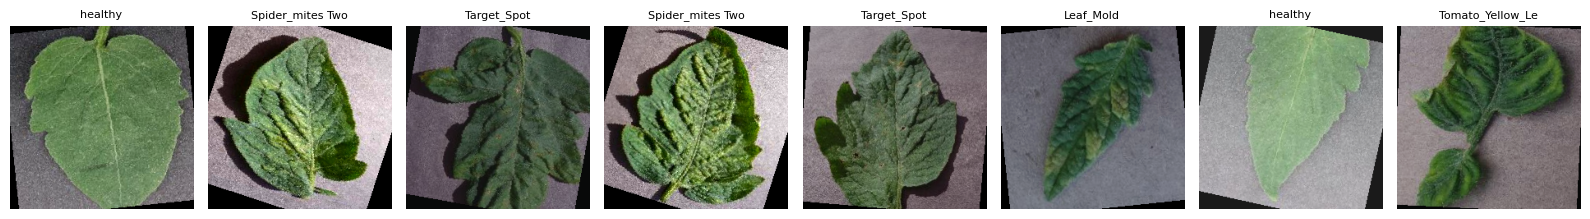

In [8]:
images, labels = next(iter(train_dl))                   # one batch
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, img, lab in zip(axes, images[:8], labels[:8]):
    img = img.permute(1, 2, 0).numpy() * STD + MEAN     # undo normalisation for display
    ax.imshow(img.clip(0, 1)); ax.set_title(CLASSES[lab][:16], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{PROJ}/figures/augmented_samples.png", dpi=200); plt.show()

## 8. Build the model
- **Pretrained models** (from `timm`): their original 1000-class ImageNet output layer is replaced
  with a new 10-class layer (**transfer learning**).
- **Baseline CNN**: a small network trained from scratch, used to show how much transfer learning helps.

In [21]:
class BaselineCNN(nn.Module):
    """4 convolution blocks -> global average pooling -> 10-class output."""
    def __init__(self, num_classes):
        super().__init__()
        def block(c_in, c_out):   # conv -> batch norm -> ReLU -> halve the image size
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
                                 nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                        nn.Dropout(0.3), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

def build_model(name):
    if name == "baseline_cnn":
        return BaselineCNN(NUM_CLASSES)
    return timm.create_model(name, pretrained=True, num_classes=NUM_CLASSES)

model = build_model(MODEL).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"{MODEL}: {n_params:.2f} million parameters")

baseline_cnn: 0.39 million parameters


## 9. Training helpers
- **Loss:** cross-entropy with label smoothing 0.1 (stops the model from being over-confident).
- **Mixed precision (float16):** about 2x faster on the T4 with the same accuracy.
- `run_epoch` does one full pass: it trains if given an optimizer, otherwise it only evaluates.
- `set_backbone_trainable` freezes or unfreezes the pretrained part of the model.

In [22]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda")

def run_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.train(training)                        # training mode or evaluation mode
    total, correct, loss_sum = 0, 0, 0.0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x)
                loss = criterion(out, y)
            if training:                         # back-propagation and weight update
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            loss_sum += loss.item() * len(y)
            correct  += (out.argmax(1) == y).sum().item()
            total    += len(y)
    return loss_sum / total, correct / total      # average loss, accuracy

def set_backbone_trainable(trainable):
    if MODEL == "baseline_cnn":                   # baseline always trains fully
        return
    head = set(id(p) for p in model.get_classifier().parameters())
    for p in model.parameters():
        p.requires_grad = trainable or id(p) in head

## 10. Train
Each epoch prints training and validation accuracy. After every epoch with a lower validation loss,
the model is saved to Drive (`weights/<model>.pt`), so a Colab disconnect doesn't lose the best result.
**Early stopping** ends a stage when validation loss stops improving.
Expected time on a T4: about 10–20 minutes per model.

In [23]:
if MODEL == "baseline_cnn":
    stages = [("full", EPOCHS_HEAD + EPOCHS_FULL, LR_HEAD)]
else:
    stages = [("head", EPOCHS_HEAD, LR_HEAD), ("full", EPOCHS_FULL, LR_FULL)]

history, best_val_loss, start = [], float("inf"), time.time()
for stage, n_epochs, lr in stages:
    set_backbone_trainable(stage == "full")
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)  # learning rate slowly decreases
    wait = 0
    for epoch in range(1, n_epochs + 1):
        t0 = time.time()
        train_loss, train_acc = run_epoch(train_dl, optimizer)
        val_loss, val_acc     = run_epoch(val_dl)
        scheduler.step()
        history.append(dict(stage=stage, epoch=len(history) + 1, train_loss=train_loss,
                            train_acc=train_acc, val_loss=val_loss, val_acc=val_acc))
        saved = ""
        if val_loss < best_val_loss:              # new best -> save to Drive
            best_val_loss, wait, saved = val_loss, 0, "  <- saved"
            torch.save(model.state_dict(), f"{PROJ}/weights/{MODEL}.pt")
        else:
            wait += 1
        print(f"[{stage}] epoch {epoch}/{n_epochs} | train acc {train_acc:.4f} | "
              f"val acc {val_acc:.4f} | val loss {val_loss:.4f} | {time.time()-t0:.0f}s{saved}")
        if wait >= PATIENCE:
            print("Early stopping"); break

train_minutes = (time.time() - start) / 60
history = pd.DataFrame(history)
history.to_csv(f"{PROJ}/results/history_{MODEL}.csv", index=False)
print(f"Finished in {train_minutes:.1f} minutes")

[full] epoch 1/10 | train acc 0.6645 | val acc 0.7259 | val loss 1.1302 | 74s  <- saved
[full] epoch 2/10 | train acc 0.7775 | val acc 0.8505 | val loss 0.9183 | 72s  <- saved
[full] epoch 3/10 | train acc 0.8202 | val acc 0.8545 | val loss 0.9105 | 72s  <- saved
[full] epoch 4/10 | train acc 0.8483 | val acc 0.9074 | val loss 0.8136 | 72s  <- saved
[full] epoch 5/10 | train acc 0.8720 | val acc 0.9074 | val loss 0.7973 | 72s  <- saved
[full] epoch 6/10 | train acc 0.8876 | val acc 0.9269 | val loss 0.7545 | 73s  <- saved
[full] epoch 7/10 | train acc 0.8999 | val acc 0.9313 | val loss 0.7465 | 71s  <- saved
[full] epoch 8/10 | train acc 0.9122 | val acc 0.9471 | val loss 0.7167 | 74s  <- saved
[full] epoch 9/10 | train acc 0.9215 | val acc 0.9427 | val loss 0.7180 | 73s
[full] epoch 10/10 | train acc 0.9251 | val acc 0.9519 | val loss 0.7025 | 72s  <- saved
Finished in 12.1 minutes


## 11. Learning curves
Training vs validation loss and accuracy per epoch. If the two lines stay close, the model is
**not overfitting**. These figures go in Chapter 5.

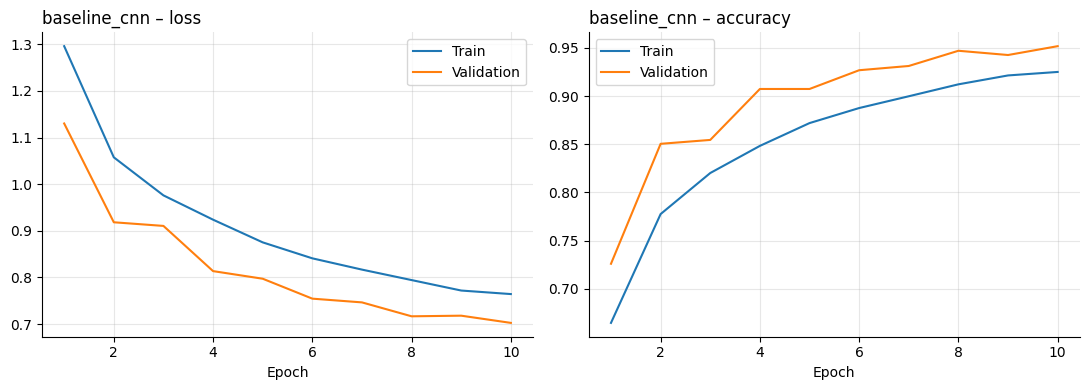

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(history.epoch, history.train_loss, label="Train"); ax1.plot(history.epoch, history.val_loss, label="Validation")
ax2.plot(history.epoch, history.train_acc,  label="Train"); ax2.plot(history.epoch, history.val_acc,  label="Validation")
ax1.set_title(f"{MODEL} – loss", loc="left"); ax2.set_title(f"{MODEL} – accuracy", loc="left")
for ax in (ax1, ax2):
    ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{PROJ}/figures/curves_{MODEL}.png", dpi=300); plt.show()

## 12. Test-set score
Loads the best saved model and scores it on the **test set** (images never seen in training).
- **Accuracy:** percentage of correct predictions
- **Macro F1:** the average F1 across all 10 classes, giving every class equal weight (important with imbalance)

Each model adds one row to `results/summary.csv`, which becomes the comparison table in Chapter 5.

In [25]:
from sklearn.metrics import accuracy_score, f1_score

model.load_state_dict(torch.load(f"{PROJ}/weights/{MODEL}.pt"))   # best epoch
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_dl:
        with torch.autocast("cuda", dtype=torch.float16):
            y_pred += model(x.to(DEVICE)).argmax(1).cpu().tolist()
        y_true += y.tolist()

row = dict(model=MODEL, test_accuracy=round(accuracy_score(y_true, y_pred), 4),
           macro_f1=round(f1_score(y_true, y_pred, average="macro"), 4),
           params_million=round(n_params, 2),
           size_MB=round(os.path.getsize(f"{PROJ}/weights/{MODEL}.pt") / 1e6, 1),
           train_minutes=round(train_minutes, 1))

summary_file = f"{PROJ}/results/summary.csv"
summary = pd.read_csv(summary_file) if os.path.exists(summary_file) else pd.DataFrame()
summary = pd.concat([summary[summary.get("model", pd.Series(dtype=str)) != MODEL], pd.DataFrame([row])])
summary.to_csv(summary_file, index=False)
summary

,model,test_accuracy,macro_f1,params_million,size_MB,train_minutes
0,efficientnet_b0,0.9974,0.9966,4.02,16.4,14.2
1,mobilenetv3_large_100,0.9941,0.9934,4.21,17.1,12.9
2,resnet50,0.9923,0.9903,23.53,94.4,14.4
0,baseline_cnn,0.9467,0.9337,0.39,1.6,12.1
